**Підготовка даних**

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
%cd /content

!git clone https://github.com/spereima/rehabilitation-project.git

%cd /content/rehabilitation-project

/content
fatal: destination path 'rehabilitation-project' already exists and is not an empty directory.
/content/rehabilitation-project


In [ ]:
%pip install -q hydra-core==1.3.2 omegaconf==2.3.0

In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [ ]:
import json
from pathlib import Path

train_subjects = [
    "16", "12", "9", "26", "19",
    "6", "5", "10", "15", "22",
    "11", "18", "1", "14", "24",
    "13", "2", "17", "25", "4", "21"
]

test_subjects = ["7", "8", "23", "0", "3", "20"]

folds = [
    ["16", "12", "9", "26", "19"],
    ["6", "5", "10", "15"],
    ["22", "11", "18", "1"],
    ["14", "24", "13", "2"],
    ["17", "25", "4", "21"]
]

output_dir = Path("data/splits/cross_validation")
output_dir.mkdir(parents=True, exist_ok=True)

assert len(train_subjects) == 21
assert len(set(train_subjects)) == 21
assert len(set(test_subjects)) == 6
assert set(train_subjects).isdisjoint(test_subjects)
assert set(subject for fold in folds for subject in fold) == set(train_subjects)

for fold_index, validation_subjects in enumerate(folds, start=1):
    training_subjects = [
        subject for subject in train_subjects
        if subject not in validation_subjects
    ]

    split = {
        "train": training_subjects,
        "val": validation_subjects,
        "test": test_subjects
    }

    file_path = output_dir / f"fold_{fold_index}.json"

    with open(file_path, "w") as file:
        json.dump(split, file, indent=4)

    print(
        f"Fold {fold_index}: "
        f"train={len(training_subjects)}, "
        f"val={len(validation_subjects)}, "
        f"test={len(test_subjects)}"
    )

Fold 1: train=16, val=5, test=6
Fold 2: train=17, val=4, test=6
Fold 3: train=17, val=4, test=6
Fold 4: train=17, val=4, test=6
Fold 5: train=17, val=4, test=6


In [ ]:
import shutil

drive_cv_dir = Path(
    "/content/drive/MyDrive/rehabilitation-project-data/"
    "cross_validation"
)

drive_cv_dir.mkdir(parents=True, exist_ok=True)

shutil.copytree(
    output_dir,
    drive_cv_dir / "splits",
    dirs_exist_ok=True
)

print("Розподіли збережено:", drive_cv_dir / "splits")

Розподіли збережено: /content/drive/MyDrive/rehabilitation-project-data/cross_validation/splits


In [ ]:
from pathlib import Path
import shutil
import zipfile

drive_root = Path(
    "/content/drive/MyDrive/rehabilitation-project-data"
)

dataset_zip = drive_root / "dataset_check_frames_small.zip"
metadata_file = drive_root / "dataset_3d_with_angles.json"

assert dataset_zip.exists(), f"Не знайдено {dataset_zip}"
assert metadata_file.exists(), f"Не знайдено {metadata_file}"

dataset_root = Path("dataset_check_frames_small")

if not dataset_root.exists():
    with zipfile.ZipFile(dataset_zip, "r") as archive:
        archive.extractall(".")

metadata_dir = Path("dataset_check")
metadata_dir.mkdir(exist_ok=True)

shutil.copy2(
    metadata_file,
    metadata_dir / "dataset_3d_with_angles.json"
)

assert dataset_root.exists()

print("Датасет і metadata підготовлені")

Датасет і metadata підготовлені


In [ ]:
output_dir = drive_root / "cross_validation" / "output"
output_dir.mkdir(parents=True, exist_ok=True)

local_output = Path("output")

if local_output.is_symlink():
    local_output.unlink()
elif local_output.exists():
    raise RuntimeError(
        "Папка output вже існує. Перевір її вміст "
        "перед створенням посилання."
    )

local_output.symlink_to(output_dir.resolve(), target_is_directory=True)

print("Результати зберігатимуться в:", output_dir)

Результати зберігатимуться в: /content/drive/MyDrive/rehabilitation-project-data/cross_validation/output


In [ ]:

experiments = [
    {
        "modality": "sils",
        "dataset_loader": "SilsFolderDataset",
        "model_name": "BaselineSilsModel",
        "channels": 1
    },
    {
        "modality": "semantic_segmentation",
        "dataset_loader": "RGBFolderDataset",
        "model_name": "BaselineRGBModel",
        "channels": 3
    }
]

print("Кількість експериментів:", len(experiments) * 5)

Кількість експериментів: 10


In [ ]:
import subprocess

def run_fold(experiment, fold_number):
    modality = experiment["modality"]
    run_name = f"{modality}_fold_{fold_number}"

    overrides = [
        "data.dataset_root=dataset_check_frames_small",
        "data.metadata_json=dataset_check/dataset_3d_with_angles.json",
        f"data.modality={modality}",
        f"data.dataset_loader={experiment['dataset_loader']}",
        f"data.channels={experiment['channels']}",
        f"+data.split_path=data/splits/cross_validation/fold_{fold_number}.json",
        f"data.split_name=fold_{fold_number}",
        "data.splits=[train,val]",
        "data.split_normalizer=train",
        "data.include_subjects=[]",
        "data.include_exercises=[]",
        "data.include_cameras=[cam0,cam1,cam2,cam3,cam4]",
        f"model.name={experiment['model_name']}",
        "model.backbone=resnet18",
        "model.hidden_dim=256",
        "training.seed=42",
        "training.epochs=10",
        "training.batch_size=16",
        "training.num_workers=2",
        "training.lr=0.0001",
        "training.weight_decay=0.05",
        "training.amp=true",
        "training.grad_clip=1.0",
        "training.device=cuda",
        "training.checkpoint_save_every=10",
        "validation.enabled=true",
        "validation.every_n_epochs=1",
        "logging.tensorboard_log=false",
        "project.name=ucophyrehab_5fold",
        f"project.run_name={run_name}"
    ]

    result_dir = (
        output_dir
        / "ucophyrehab_5fold"
        / modality
        / f"fold_{fold_number}"
        / run_name
    )

    log_path = result_dir / "logs" / "train_log.txt"

    if log_path.exists():
        if "CV_FINISHED" in log_path.read_text():
            print(f"Уже завершено: {run_name}")
            return

    print(f"\n{'=' * 55}")
    print(f"Запуск: {run_name}")
    print(f"{'=' * 55}")

    overrides = [
      "++" + override.lstrip("+")
      for override in overrides
  ]

    manifest_command = [
        "python", "-m", "src.cli.build_manifest",
        *overrides
    ]

    subprocess.run(manifest_command, check=True)

    train_command = [
        "python", "-m", "src.cli.train_cv",
        *overrides
    ]

    subprocess.run(train_command, check=True)

    if not log_path.exists():
        raise RuntimeError(f"Не знайдено лог: {log_path}")

    if "CV_FINISHED" not in log_path.read_text():
        raise RuntimeError(
            f"Навчання {run_name} не має позначки завершення"
        )

    print(f"Завершено: {run_name}")

In [ ]:
run_fold(experiments[0], 1)


Запуск: sils_fold_1
Завершено: sils_fold_1


**Перевірка на 1 фолді**

In [ ]:
log_path = (
    output_dir
    / "ucophyrehab_5fold"
    / "sils"
    / "fold_1"
    / "sils_fold_1"
    / "logs"
    / "train_log.txt"
)

print("\n".join(log_path.read_text().splitlines()[-25:]))

Using device: cuda
[train] Epoch 1: Loss=0.0405, MAE=3.846, RMSE=4.926
[validation] Epoch 1: Loss=0.2937, MAE=11.831, RMSE=12.102
[save] best checkpoint -> output/ucophyrehab_5fold/sils/fold_1/sils_fold_1/checkpoints/best.pth, MAE=11.831
[train] Epoch 2: Loss=0.0088, MAE=2.014, RMSE=2.619
[validation] Epoch 2: Loss=0.1915, MAE=9.817, RMSE=10.083
[save] best checkpoint -> output/ucophyrehab_5fold/sils/fold_1/sils_fold_1/checkpoints/best.pth, MAE=9.817
[train] Epoch 3: Loss=0.0057, MAE=1.635, RMSE=2.123
[validation] Epoch 3: Loss=0.2520, MAE=10.823, RMSE=11.058
[train] Epoch 4: Loss=0.0045, MAE=1.431, RMSE=1.862
[validation] Epoch 4: Loss=0.2245, MAE=10.101, RMSE=10.348
[train] Epoch 5: Loss=0.0035, MAE=1.288, RMSE=1.669
[validation] Epoch 5: Loss=0.2349, MAE=10.524, RMSE=10.775
[train] Epoch 6: Loss=0.0029, MAE=1.187, RMSE=1.535
[validation] Epoch 6: Loss=0.2628, MAE=10.802, RMSE=11.054
[train] Epoch 7: Loss=0.0029, MAE=1.115, RMSE=1.449
[validation] Epoch 7: Loss=0.2394, MAE=10.405, RM

**5-fold Cross-Validation**




In [ ]:
from tqdm.auto import tqdm
from pathlib import Path
import threading
import time
import re


def run_sils_with_progress():
    modality = "sils"
    total_folds = 5
    total_epochs = 10

    with tqdm(
        total=total_folds,
        desc="SILS — загальний прогрес",
        unit="fold",
        position=0
    ) as overall_bar:

        for fold_number in range(1, total_folds + 1):

            run_name = f"sils_fold_{fold_number}"

            log_path = (
                output_dir
                / "ucophyrehab_5fold"
                / modality
                / f"fold_{fold_number}"
                / run_name
                / "logs"
                / "train_log.txt"
            )

            if log_path.exists():
                log_text = log_path.read_text(errors="replace")

                if "CV_FINISHED" in log_text:
                    overall_bar.update(1)
                    tqdm.write(f"Fold {fold_number} уже завершений")
                    continue

            with tqdm(
                total=total_epochs,
                desc=f"SILS Fold {fold_number} — епохи",
                unit="epoch",
                position=1,
                leave=False
            ) as epoch_bar:

                finished = threading.Event()
                errors = []

                def train_worker():
                    try:
                        run_fold(experiments[0], fold_number)
                    except Exception as error:
                        errors.append(error)
                    finally:
                        finished.set()

                worker = threading.Thread(
                    target=train_worker,
                    daemon=True
                )

                worker.start()

                while not finished.is_set():

                    if log_path.exists():
                        log_text = log_path.read_text(
                            errors="replace"
                        )

                        completed_epochs = [
                            int(epoch)
                            for epoch in re.findall(
                                r"\[validation\] Epoch (\d+):",
                                log_text
                            )
                        ]

                        if completed_epochs:
                            latest_epoch = min(
                                max(completed_epochs),
                                total_epochs
                            )

                            if latest_epoch > epoch_bar.n:
                                epoch_bar.update(
                                    latest_epoch - epoch_bar.n
                                )

                    time.sleep(10)

                worker.join()

                if errors:
                    raise errors[0]

                if log_path.exists():
                    log_text = log_path.read_text(
                        errors="replace"
                    )

                    if "CV_FINISHED" in log_text:
                        epoch_bar.update(
                            total_epochs - epoch_bar.n
                        )
                    else:
                        raise RuntimeError(
                            f"Fold {fold_number} не завершився"
                        )

            overall_bar.update(1)
            tqdm.write(f"Fold {fold_number} завершено!")

    print("Усі 5 фолдів SILS успішно завершено!")

In [ ]:
run_sils_with_progress()

SILS — загальний прогрес:   0%|          | 0/5 [00:00<?, ?fold/s]

Fold 1 уже завершений


SILS Fold 2 — епохи:   0%|          | 0/10 [00:00<?, ?epoch/s]


Запуск: sils_fold_2
Завершено: sils_fold_2
Fold 2 завершено!


SILS Fold 3 — епохи:   0%|          | 0/10 [00:00<?, ?epoch/s]


Запуск: sils_fold_3
Завершено: sils_fold_3
Fold 3 завершено!


SILS Fold 4 — епохи:   0%|          | 0/10 [00:00<?, ?epoch/s]


Запуск: sils_fold_4
Завершено: sils_fold_4
Fold 4 завершено!


SILS Fold 5 — епохи:   0%|          | 0/10 [00:00<?, ?epoch/s]


Запуск: sils_fold_5
Завершено: sils_fold_5
Fold 5 завершено!
Усі 5 фолдів SILS успішно завершено!


In [ ]:
from tqdm.auto import tqdm
from pathlib import Path
import threading
import time
import re


def run_semantic_with_progress():
    modality = "semantic_segmentation"
    total_folds = 5
    total_epochs = 10

    with tqdm(
        total=total_folds,
        desc="Semantic Segmentation — загальний прогрес",
        unit="fold",
        position=0
    ) as overall_bar:

        for fold_number in range(1, total_folds + 1):

            run_name = f"{modality}_fold_{fold_number}"

            log_path = (
                output_dir
                / "ucophyrehab_5fold"
                / modality
                / f"fold_{fold_number}"
                / run_name
                / "logs"
                / "train_log.txt"
            )

            if log_path.exists():
                log_text = log_path.read_text(errors="replace")

                if "CV_FINISHED" in log_text:
                    overall_bar.update(1)
                    tqdm.write(
                        f"Semantic Segmentation Fold {fold_number} уже завершений"
                    )
                    continue

            with tqdm(
                total=total_epochs,
                desc=f"Semantic Fold {fold_number} — епохи",
                unit="epoch",
                position=1,
                leave=False
            ) as epoch_bar:

                finished = threading.Event()
                errors = []

                def train_worker():
                    try:
                        run_fold(experiments[1], fold_number)
                    except Exception as error:
                        errors.append(error)
                    finally:
                        finished.set()

                worker = threading.Thread(
                    target=train_worker,
                    daemon=True
                )

                worker.start()

                while not finished.is_set():

                    if log_path.exists():
                        log_text = log_path.read_text(
                            errors="replace"
                        )

                        completed_epochs = [
                            int(epoch)
                            for epoch in re.findall(
                                r"\[validation\] Epoch (\d+):",
                                log_text
                            )
                        ]

                        if completed_epochs:
                            latest_epoch = min(
                                max(completed_epochs),
                                total_epochs
                            )

                            if latest_epoch > epoch_bar.n:
                                epoch_bar.update(
                                    latest_epoch - epoch_bar.n
                                )

                    time.sleep(10)

                worker.join()

                if errors:
                    raise errors[0]

                if log_path.exists():
                    log_text = log_path.read_text(
                        errors="replace"
                    )

                    if "CV_FINISHED" in log_text:
                        epoch_bar.update(
                            total_epochs - epoch_bar.n
                        )
                    else:
                        raise RuntimeError(
                            f"Semantic Fold {fold_number} не завершився"
                        )

            overall_bar.update(1)

            tqdm.write(
                f"Semantic Segmentation Fold {fold_number} завершено!"
            )

    print("Усі 5 фолдів Semantic Segmentation завершено!")

In [ ]:
run_semantic_with_progress()

Semantic Segmentation — загальний прогрес:   0%|          | 0/5 [00:00<?, ?fold/s]

Semantic Segmentation Fold 1 уже завершений
Semantic Segmentation Fold 2 уже завершений
Semantic Segmentation Fold 3 уже завершений
Semantic Segmentation Fold 4 уже завершений


Semantic Fold 5 — епохи:   0%|          | 0/10 [00:00<?, ?epoch/s]


Запуск: semantic_segmentation_fold_5
Завершено: semantic_segmentation_fold_5
Semantic Segmentation Fold 5 завершено!
Усі 5 фолдів Semantic Segmentation завершено!


**Аналіз результатів Cross-Validation**

In [ ]:
from pathlib import Path
import torch
import pandas as pd

output_root = Path(
    "/content/drive/MyDrive/rehabilitation-project-data/"
    "cross_validation/output/ucophyrehab_5fold"
)

results = []

for modality in ["sils", "semantic_segmentation"]:
    for fold_number in range(1, 6):

        run_name = f"{modality}_fold_{fold_number}"

        checkpoint_path = (
            output_root
            / modality
            / f"fold_{fold_number}"
            / run_name
            / "checkpoints"
            / "best.pth"
        )

        if not checkpoint_path.exists():
            print("Не знайдено:", checkpoint_path)
            continue

        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=False
        )

        results.append({
            "modality": modality,
            "fold": fold_number,
            "best_epoch": checkpoint["epoch"],
            "validation_mae": checkpoint["best_val_mae"]
        })

results_df = pd.DataFrame(results)

display(results_df)

,modality,fold,best_epoch,validation_mae
0,sils,1,2,9.817084
1,sils,2,3,8.640771
2,sils,3,3,8.310026
3,sils,4,3,7.241661
4,sils,5,9,8.863784
5,semantic_segmentation,1,7,8.495999
6,semantic_segmentation,2,2,7.611867
7,semantic_segmentation,3,3,7.799269
8,semantic_segmentation,4,1,7.210314
9,semantic_segmentation,5,6,8.614176


In [ ]:
summary = results_df.groupby("modality").agg(
    mean_mae=("validation_mae", "mean"),
    std_mae=("validation_mae", "std"),
    min_mae=("validation_mae", "min"),
    max_mae=("validation_mae", "max"),
    mean_best_epoch=("best_epoch", "mean"),
    median_best_epoch=("best_epoch", "median"),
    folds=("fold", "count")
)

display(summary.round(3))

,mean_mae,std_mae,min_mae,max_mae,mean_best_epoch,median_best_epoch,folds
modality,,,,,,,
semantic_segmentation,7.946,0.597,7.210,8.614,3.8,3.0,5
sils,8.575,0.933,7.242,9.817,4.0,3.0,5


In [ ]:
import re

epoch_results = []

for modality in ["sils", "semantic_segmentation"]:
    for fold_number in range(1, 6):

        run_name = f"{modality}_fold_{fold_number}"

        log_path = (
            output_root
            / modality
            / f"fold_{fold_number}"
            / run_name
            / "logs"
            / "train_log.txt"
        )

        if not log_path.exists():
            print("Не знайдено лог:", log_path)
            continue

        log_text = log_path.read_text(errors="replace")

        matches = re.findall(
            r"\[validation\] Epoch (\d+): "
            r"Loss=([\d.]+), MAE=([\d.]+), RMSE=([\d.]+)",
            log_text
        )

        for epoch, loss, mae, rmse in matches:
            epoch_results.append({
                "modality": modality,
                "fold": fold_number,
                "epoch": int(epoch),
                "validation_mae": float(mae),
                "validation_rmse": float(rmse)
            })

epoch_df = pd.DataFrame(epoch_results)

display(epoch_df)

,modality,fold,epoch,validation_mae,validation_rmse
0,sils,1,1,11.831,12.102
1,sils,1,2,9.817,10.083
2,sils,1,3,10.823,11.058
3,sils,1,4,10.101,10.348
4,sils,1,5,10.524,10.775
...,...,...,...,...,...
89,semantic_segmentation,5,6,8.614,8.840
90,semantic_segmentation,5,7,8.950,9.187
91,semantic_segmentation,5,8,8.657,8.899
92,semantic_segmentation,5,9,9.024,9.259


In [ ]:
epoch_summary = (
    epoch_df
    .groupby(["modality", "epoch"])
    .agg(
        mean_mae=("validation_mae", "mean"),
        std_mae=("validation_mae", "std"),
        folds=("fold", "nunique")
    )
    .reset_index()
)

display(epoch_summary.round(3))

,modality,epoch,mean_mae,std_mae,folds
0,semantic_segmentation,1,8.662,1.138,4
1,semantic_segmentation,2,8.347,1.134,4
2,semantic_segmentation,3,8.108,0.539,4
3,semantic_segmentation,4,8.552,0.913,5
4,semantic_segmentation,5,8.596,0.700,5
5,semantic_segmentation,6,8.492,0.762,5
6,semantic_segmentation,7,8.185,0.640,5
7,semantic_segmentation,8,8.153,0.543,5
8,semantic_segmentation,9,8.184,0.753,5
9,semantic_segmentation,10,8.210,0.575,5


In [ ]:
for modality in ["sils", "semantic_segmentation"]:
    print("\nМодель:", modality)

    for fold_number in range(1, 6):
        fold_data = epoch_df[
            (epoch_df["modality"] == modality)
            & (epoch_df["fold"] == fold_number)
        ]

        available_epochs = sorted(
            fold_data["epoch"].unique().tolist()
        )

        missing_epochs = []

        for epoch in range(1, 11):
            if epoch not in available_epochs:
                missing_epochs.append(epoch)

        best_data = results_df[
            (results_df["modality"] == modality)
            & (results_df["fold"] == fold_number)
        ]

        print(
            f"Fold {fold_number}: "
            f"епохи={available_epochs}, "
            f"відсутні={missing_epochs}, "
            f"best_epoch={best_data['best_epoch'].iloc[0]}"
        )


Модель: sils
Fold 1: епохи=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10], відсутні=[], best_epoch=2
Fold 2: епохи=[4, 5, 6, 7, 8, 9, 10], відсутні=[1, 2, 3], best_epoch=3
Fold 3: епохи=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10], відсутні=[], best_epoch=3
Fold 4: епохи=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10], відсутні=[], best_epoch=3
Fold 5: епохи=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10], відсутні=[], best_epoch=9

Модель: semantic_segmentation
Fold 1: епохи=[4, 5, 6, 7, 8, 9, 10], відсутні=[1, 2, 3], best_epoch=7
Fold 2: епохи=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10], відсутні=[], best_epoch=2
Fold 3: епохи=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10], відсутні=[], best_epoch=3
Fold 4: епохи=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10], відсутні=[], best_epoch=1
Fold 5: епохи=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10], відсутні=[], best_epoch=6


In [ ]:
complete_epochs = epoch_summary[
    epoch_summary["folds"] == 5
].copy()

display(
    complete_epochs.sort_values(
        ["modality", "mean_mae"]
    ).round(3)
)

,modality,epoch,mean_mae,std_mae,folds
7,semantic_segmentation,8,8.153,0.543,5
8,semantic_segmentation,9,8.184,0.753,5
6,semantic_segmentation,7,8.185,0.640,5
9,semantic_segmentation,10,8.210,0.575,5
5,semantic_segmentation,6,8.492,0.762,5
3,semantic_segmentation,4,8.552,0.913,5
4,semantic_segmentation,5,8.596,0.700,5
17,sils,8,8.984,0.994,5
18,sils,9,9.005,1.089,5
13,sils,4,9.018,0.826,5


**Фінальне навчання моделей**

In [ ]:
from pathlib import Path
import json

cv_subjects = [
    "16", "12", "9", "26", "19",
    "6", "5", "10", "15",
    "22", "11", "18", "1",
    "14", "24", "13", "2",
    "17", "25", "4", "21"
]

test_subjects = ["7", "8", "23", "0", "3", "20"]

assert len(cv_subjects) == 21
assert len(set(cv_subjects)) == 21
assert not set(cv_subjects) & set(test_subjects)

final_split = {
    "train": cv_subjects,
    "val": [],
    "test": test_subjects
}

split_path = Path(
    "data/splits/cross_validation/final_train.json"
)

split_path.parent.mkdir(parents=True, exist_ok=True)

with open(split_path, "w") as file:
    json.dump(final_split, file, indent=4)

print("Створено:", split_path)
print("Train:", len(final_split["train"]))
print("Test:", len(final_split["test"]))

Створено: data/splits/cross_validation/final_train.json
Train: 21
Test: 6


In [ ]:
import subprocess

def run_final(experiment, epochs=3):
    modality = experiment["modality"]
    run_name = f"{modality}_final"

    overrides = [
        "data.dataset_root=dataset_check_frames_small",
        "data.metadata_json=dataset_check/dataset_3d_with_angles.json",
        f"data.modality={modality}",
        f"data.dataset_loader={experiment['dataset_loader']}",
        f"data.channels={experiment['channels']}",
        "data.split_path=data/splits/cross_validation/final_train.json",
        "data.split_name=final_train",
        "data.splits=[train]",
        "data.split_normalizer=train",
        "data.include_subjects=[]",
        "data.include_exercises=[]",
        "data.include_cameras=[cam0,cam1,cam2,cam3,cam4]",
        f"model.name={experiment['model_name']}",
        "model.backbone=resnet18",
        "model.hidden_dim=256",
        "training.seed=42",
        f"training.epochs={epochs}",
        "training.batch_size=16",
        "training.num_workers=2",
        "training.lr=0.0001",
        "training.weight_decay=0.05",
        "training.amp=true",
        "training.grad_clip=1.0",
        "training.device=cuda",
        "training.checkpoint_save_every=1",
        "validation.enabled=false",
        "logging.tensorboard_log=false",
        "project.name=ucophyrehab_final",
        f"project.run_name={run_name}"
    ]

    overrides = [
        "++" + override.lstrip("+")
        for override in overrides
    ]

    result_dir = (
        output_dir
        / "ucophyrehab_final"
        / modality
        / "final_train"
        / run_name
    )

    checkpoint_path = (
        result_dir
        / "checkpoints"
        / f"epoch_{epochs}.pth"
    )

    if checkpoint_path.exists():
        print(f"Уже завершено: {run_name}")
        return

    print(f"Підготовка даних: {run_name}")

    subprocess.run(
        ["python", "-m", "src.cli.build_manifest", *overrides],
        check=True
    )

    print(f"Навчання: {run_name}")

    subprocess.run(
        ["python", "-m", "src.cli.train_final", *overrides],
        check=True
    )

    if not checkpoint_path.exists():
        raise RuntimeError(
            f"Не знайдено фінальний checkpoint: {checkpoint_path}"
        )

    print(f"Завершено: {run_name}")

In [ ]:
import threading
import time
import re
from pathlib import Path
from tqdm.auto import tqdm


def run_final_with_progress(experiment, epochs=3):
    modality = experiment["modality"]
    run_name = f"{modality}_final"

    result_dir = (
        output_dir
        / "ucophyrehab_final"
        / modality
        / "final_train"
        / run_name
    )

    log_path = result_dir / "logs" / "train_log.txt"

    checkpoint_dir = result_dir / "checkpoints"

    final_checkpoint = checkpoint_dir / f"epoch_{epochs}.pth"

    if final_checkpoint.exists():
        print(f"Уже завершено: {run_name}")
        return

    errors = []

    def training_worker():
        try:
            run_final(experiment, epochs=epochs)
        except Exception as error:
            errors.append(error)

    worker = threading.Thread(target=training_worker)

    print(f"\nНавчання: {modality}")

    with tqdm(
        total=epochs,
        desc=f"{modality} — епохи",
        unit="епоха"
    ) as epoch_bar:

        completed_epochs = 0

        for epoch in range(1, epochs + 1):
            checkpoint = checkpoint_dir / f"epoch_{epoch}.pth"

            if checkpoint.exists():
                completed_epochs = epoch

        epoch_bar.update(completed_epochs)

        worker.start()

        while worker.is_alive():

            current_epoch = completed_epochs

            for epoch in range(1, epochs + 1):
                checkpoint = checkpoint_dir / f"epoch_{epoch}.pth"

                if checkpoint.exists():
                    current_epoch = max(current_epoch, epoch)

            if log_path.exists():
                log_text = log_path.read_text(errors="replace")

                matches = re.findall(
                    r"\[train\] Epoch (\d+):",
                    log_text
                )

                if matches:
                    current_epoch = max(
                        current_epoch,
                        max(int(epoch) for epoch in matches)
                    )

            if current_epoch > epoch_bar.n:
                epoch_bar.update(current_epoch - epoch_bar.n)

            time.sleep(5)

        worker.join()

        if errors:
            raise errors[0]

        if final_checkpoint.exists():
            epoch_bar.update(epochs - epoch_bar.n)

    print(f"Завершено: {modality}")

In [ ]:
run_final_with_progress(experiments[0], epochs=3)


Навчання: sils


sils — епохи:   0%|          | 0/3 [00:00<?, ?епоха/s]

Підготовка даних: sils_final
Навчання: sils_final
Завершено: sils_final
Завершено: sils


In [ ]:
run_final_with_progress(experiments[1], epochs=3)


Навчання: semantic_segmentation


semantic_segmentation — епохи:   0%|          | 0/3 [00:00<?, ?епоха/s]

Підготовка даних: semantic_segmentation_final
Навчання: semantic_segmentation_final
Завершено: semantic_segmentation_final
Завершено: semantic_segmentation


**Тестування фінальних моделей**

In [ ]:
import subprocess
from pathlib import Path

for experiment in experiments:
    modality = experiment["modality"]
    run_name = f"{modality}_final"

    overrides = [
        "data.dataset_root=dataset_check_frames_small",
        "data.metadata_json=dataset_check/dataset_3d_with_angles.json",
        f"data.modality={modality}",
        f"data.dataset_loader={experiment['dataset_loader']}",
        f"data.channels={experiment['channels']}",
        "data.split_path=data/splits/cross_validation/final_train.json",
        "data.split_name=final_train",
        "data.splits=[test]",
        "data.split_normalizer=train",
        "data.include_subjects=[]",
        "data.include_exercises=[]",
        "data.include_cameras=[cam0,cam1,cam2,cam3,cam4]",
        f"model.name={experiment['model_name']}",
        "model.backbone=resnet18",
        "model.hidden_dim=256",
        "project.name=ucophyrehab_final",
        f"project.run_name={run_name}"
    ]

    overrides = [
        "++" + override.lstrip("+")
        for override in overrides
    ]

    print(f"\nСтворюємо test manifest: {modality}")

    subprocess.run(
        ["python", "-m", "src.cli.build_manifest", *overrides],
        check=True
    )

    manifest_path = (
        Path("data/manifests")
        / "ucophyrehab_final"
        / modality
        / "final_train"
        / run_name
        / "final_train_test.csv"
    )

    assert manifest_path.exists(), (
        f"Не знайдено test manifest: {manifest_path}"
    )

    print("Готово:", manifest_path)


Створюємо test manifest: sils
Готово: data/manifests/ucophyrehab_final/sils/final_train/sils_final/final_train_test.csv

Створюємо test manifest: semantic_segmentation
Готово: data/manifests/ucophyrehab_final/semantic_segmentation/final_train/semantic_segmentation_final/final_train_test.csv


In [ ]:
import pandas as pd
from pathlib import Path

expected_test_subjects = {"7", "8", "23", "0", "3", "20"}
test_manifests = {}

for modality in ["sils", "semantic_segmentation"]:

    manifest_path = (
        Path("data/manifests")
        / "ucophyrehab_final"
        / modality
        / "final_train"
        / f"{modality}_final"
        / "final_train_test.csv"
    )

    df = pd.read_csv(
        manifest_path,
        dtype={"subject": str}
    )

    test_manifests[modality] = df

    actual_subjects = set(df["subject"])

    print(f"\nМодель: {modality}")
    print("Кількість кадрів:", len(df))
    print("Учасники:", sorted(actual_subjects))
    print("Кількість вправ:", df["exercise"].nunique())
    print("Кількість камер:", df["camera"].nunique())

    assert len(df) > 0, "Тестова вибірка порожня"

    assert actual_subjects == expected_test_subjects, (
        f"Некоректний набір учасників: {actual_subjects}"
    )

    missing_images = [
        path for path in df["img_path"]
        if not Path(path).exists()
    ]

    print("Відсутні зображення:", len(missing_images))

    assert not missing_images, (
        "Деякі зображення відсутні"
    )

print("\nУсі перевірки пройдено!")


Модель: sils
Кількість кадрів: 223335
Учасники: ['0', '20', '23', '3', '7', '8']
Кількість вправ: 16
Кількість камер: 5
Відсутні зображення: 0

Модель: semantic_segmentation
Кількість кадрів: 223335
Учасники: ['0', '20', '23', '3', '7', '8']
Кількість вправ: 16
Кількість камер: 5
Відсутні зображення: 0

Усі перевірки пройдено!


In [ ]:
import subprocess

def run_final_test(experiment):

    modality = experiment["modality"]

    overrides = [
        "data.dataset_root=dataset_check_frames_small",
        "data.metadata_json=dataset_check/dataset_3d_with_angles.json",
        f"data.modality={modality}",
        f"data.dataset_loader={experiment['dataset_loader']}",
        f"data.channels={experiment['channels']}",
        "data.split_path=data/splits/cross_validation/final_train.json",
        "data.split_name=final_train",
        "data.splits=[test]",
        "data.split_normalizer=train",
        "data.include_subjects=[]",
        "data.include_exercises=[]",
        "data.include_cameras=[cam0,cam1,cam2,cam3,cam4]",
        f"model.name={experiment['model_name']}",
        "model.backbone=resnet18",
        "model.hidden_dim=256",
        "training.batch_size=16",
        "training.num_workers=2",
        "training.device=cuda",
        "project.name=ucophyrehab_final",
        f"project.run_name={modality}_final"
    ]

    overrides = [
        "++" + override.lstrip("+")
        for override in overrides
    ]

    subprocess.run(
        [
            "python",
            "-m",
            "src.cli.test_final",
            *overrides
        ],
        check=True
    )

In [ ]:
run_final_test(experiments[0])

In [ ]:
run_final_test(experiments[1])

In [ ]:
import json
import pandas as pd
from pathlib import Path

results_root = (
    Path("/content/drive/MyDrive/rehabilitation-project-data")
    / "cross_validation"
    / "output"
    / "ucophyrehab_final"
    / "test_results"
)

summaries = []

for modality in ["sils", "semantic_segmentation"]:

    summary_path = (
        results_root / modality / "summary.json"
    )

    with open(summary_path) as file:
        summaries.append(json.load(file))

comparison = pd.DataFrame(summaries)

display(comparison.round(4))

,modality,test_frames,test_mae,test_rmse,checkpoint_epoch
0,sils,223335,12.7885,18.3083,3
1,semantic_segmentation,223335,11.5036,16.3478,3


**Порівняння моделей та аналіз похибок**

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

results_root = (
    Path("/content/drive/MyDrive/rehabilitation-project-data")
    / "cross_validation"
    / "output"
    / "ucophyrehab_final"
    / "test_results"
)

predictions = {}

for modality in ["sils", "semantic_segmentation"]:
    path = results_root / modality / "all_predictions.csv"

    predictions[modality] = pd.read_csv(
        path,
        dtype={"subject": str}
    )

keys = ["subject", "exercise", "camera", "frame_id"]

sils = predictions["sils"]
semantic = predictions["semantic_segmentation"]

assert not sils.duplicated(keys).any()
assert not semantic.duplicated(keys).any()

merged = sils.merge(
    semantic,
    on=keys,
    suffixes=("_sils", "_semantic"),
    validate="one_to_one"
)

assert len(merged) == len(sils) == len(semantic)
assert np.allclose(
    merged["ground_truth_angle_sils"],
    merged["ground_truth_angle_semantic"]
)

print("Кадри обох моделей повністю збігаються.")
print("Кількість спільних кадрів:", len(merged))


def calculate_metrics(df, group_columns):
    result = (
        df.groupby(group_columns)
        .agg(
            frames=("absolute_error", "size"),
            mae=("absolute_error", "mean"),
            mse=("squared_error", "mean")
        )
        .reset_index()
    )

    result["rmse"] = np.sqrt(result["mse"])
    return result.drop(columns="mse")


for group_name, group_columns in [
    ("subject", ["subject"]),
    ("exercise", ["exercise"]),
    ("camera", ["camera"])
]:
    tables = []

    for modality, df in predictions.items():
        metrics = calculate_metrics(df, group_columns)
        metrics["modality"] = modality
        tables.append(metrics)

    comparison_table = pd.concat(
        tables,
        ignore_index=True
    )

    output_path = results_root / f"comparison_by_{group_name}.csv"

    comparison_table.to_csv(output_path, index=False)

    print(f"\n{'=' * 55}")
    print(f"ПОРІВНЯННЯ ЗА {group_name.upper()}")
    print(f"{'=' * 55}")

    display(comparison_table.round(3))

Кадри обох моделей повністю збігаються.
Кількість спільних кадрів: 223335

ПОРІВНЯННЯ ЗА SUBJECT


,subject,frames,mae,rmse,modality
0,0,39682,14.518,20.566,sils
1,20,50211,14.717,20.929,sils
2,23,9617,7.088,10.291,sils
3,3,101989,12.652,17.759,sils
4,7,6797,6.987,8.786,sils
5,8,15039,8.980,12.564,sils
6,0,39682,12.957,18.238,semantic_segmentation
7,20,50211,9.366,13.114,semantic_segmentation
8,23,9617,7.703,10.385,semantic_segmentation
9,3,101989,13.024,18.264,semantic_segmentation



ПОРІВНЯННЯ ЗА EXERCISE


,exercise,frames,mae,rmse,modality
0,1,18528,8.435,12.084,sils
1,2,20586,10.905,16.518,sils
2,3,14655,5.269,6.824,sils
3,4,19177,16.608,22.319,sils
4,5,12681,11.309,14.706,sils
5,6,14557,12.982,16.939,sils
6,7,16442,4.441,5.511,sils
7,8,18492,15.693,21.348,sils
8,9,22346,18.373,24.455,sils
9,10,1655,16.812,19.549,sils



ПОРІВНЯННЯ ЗА CAMERA


,camera,frames,mae,rmse,modality
0,cam0,69835,7.640,10.770,sils
1,cam1,38380,15.191,20.162,sils
2,cam2,38377,13.351,18.863,sils
3,cam3,38374,14.569,20.741,sils
4,cam4,38369,17.412,23.392,sils
5,cam0,69835,7.976,10.676,semantic_segmentation
6,cam1,38380,12.268,16.614,semantic_segmentation
7,cam2,38377,9.135,12.744,semantic_segmentation
8,cam3,38374,16.273,21.974,semantic_segmentation
9,cam4,38369,14.758,20.656,semantic_segmentation


In [ ]:
import numpy as np
import pandas as pd

comparison = (
    merged.groupby(["exercise", "camera"])
    .agg(
        frames=("absolute_error_sils", "size"),
        sils_mae=("absolute_error_sils", "mean"),
        semantic_mae=("absolute_error_semantic", "mean")
    )
    .reset_index()
)

comparison["improvement"] = (
    comparison["sils_mae"]
    - comparison["semantic_mae"]
)

heatmap_data = comparison.pivot(
    index="exercise",
    columns="camera",
    values="improvement"
)

display(heatmap_data.round(2))

comparison.to_csv(
    results_root / "comparison_exercise_camera.csv",
    index=False
)

camera,cam0,cam1,cam2,cam3,cam4
exercise,,,,,
1,-0.94,3.08,-1.66,-3.14,-1.80
2,-0.71,5.67,-0.50,-1.94,-1.93
3,-0.11,-0.63,-1.57,0.01,-3.84
4,0.27,11.31,9.51,12.57,16.01
5,-1.02,0.70,-0.34,-19.93,-2.99
6,-0.18,2.05,1.75,-22.50,-2.45
7,-0.07,-1.10,-1.79,-14.84,-1.30
8,-0.07,13.31,2.13,19.13,-0.18
9,-1.36,6.31,7.41,-9.23,9.45


In [ ]:
detailed_comparison = comparison[
    [
        "exercise",
        "camera",
        "frames",
        "sils_mae",
        "semantic_mae",
        "improvement"
    ]
].copy()

detailed_comparison["better_model"] = "semantic_segmentation"

detailed_comparison.loc[
    detailed_comparison["improvement"] < 0,
    "better_model"
] = "sils"

detailed_comparison = detailed_comparison.sort_values(
    "improvement",
    key=abs,
    ascending=False
)

display(detailed_comparison.head(20).round(3))

,exercise,camera,frames,sils_mae,semantic_mae,improvement,better_model
48,11,cam2,1710,38.314,6.137,32.177,semantic_segmentation
70,15,cam4,1001,52.300,21.152,31.147,semantic_segmentation
68,15,cam2,1001,36.702,8.052,28.650,semantic_segmentation
28,6,cam3,2489,19.099,41.598,-22.499,sils
69,15,cam3,1001,48.141,26.250,21.891,semantic_segmentation
23,5,cam3,2196,8.867,28.798,-19.931,sils
38,8,cam3,3191,32.037,12.906,19.131,semantic_segmentation
19,4,cam4,3323,27.391,11.384,16.007,semantic_segmentation
33,7,cam3,2884,7.256,22.093,-14.837,sils
50,11,cam4,1710,22.215,8.156,14.059,semantic_segmentation


In [ ]:
import numpy as np
import pandas as pd

error_summary = []

for modality, df in predictions.items():

    error = (
        df["predicted_angle"]
        - df["ground_truth_angle"]
    )

    absolute_error = error.abs()

    error_summary.append({
        "modality": modality,
        "frames": len(df),
        "MAE": absolute_error.mean(),
        "RMSE": np.sqrt((error ** 2).mean()),
        "Median_AE": absolute_error.median(),
        "P90_AE": absolute_error.quantile(0.90),
        "P95_AE": absolute_error.quantile(0.95),
        "Bias": error.mean(),
        "Error_over_5_pct": (absolute_error > 5).mean() * 100,
        "Error_over_10_pct": (absolute_error > 10).mean() * 100,
        "Error_over_15_pct": (absolute_error > 15).mean() * 100,
        "Error_over_20_pct": (absolute_error > 20).mean() * 100,
        "Error_over_30_pct": (absolute_error > 30).mean() * 100
    })

error_summary = pd.DataFrame(error_summary)

display(error_summary.round(3))

error_summary.to_csv(
    results_root / "error_analysis_summary.csv",
    index=False
)

,modality,frames,MAE,RMSE,Median_AE,P90_AE,P95_AE,Bias,Error_over_5_pct,Error_over_10_pct,Error_over_15_pct,Error_over_20_pct,Error_over_30_pct
0,sils,223335,12.788,18.308,8.081,32.901,41.806,-0.621,65.795,42.255,28.602,21.168,12.117
1,semantic_segmentation,223335,11.504,16.348,7.926,27.043,36.647,-5.646,67.214,39.538,24.143,16.181,8.284


In [ ]:
frame_comparison = merged.copy()

frame_comparison["error_difference"] = (
    frame_comparison["absolute_error_sils"]
    - frame_comparison["absolute_error_semantic"]
)

semantic_better = (
    frame_comparison["error_difference"] > 0
).mean() * 100

sils_better = (
    frame_comparison["error_difference"] < 0
).mean() * 100

equal_error = (
    frame_comparison["error_difference"] == 0
).mean() * 100

print(f"Semantic краща: {semantic_better:.2f}% кадрів")
print(f"SILS краща: {sils_better:.2f}% кадрів")
print(f"Однакова похибка: {equal_error:.2f}% кадрів")

frame_comparison[
    [
        "subject",
        "exercise",
        "camera",
        "frame_id",
        "ground_truth_angle_sils",
        "predicted_angle_sils",
        "predicted_angle_semantic",
        "absolute_error_sils",
        "absolute_error_semantic",
        "error_difference"
    ]
].to_csv(
    results_root / "frame_error_comparison.csv",
    index=False
)

Semantic краща: 50.13% кадрів
SILS краща: 49.77% кадрів
Однакова похибка: 0.10% кадрів


In [ ]:
for modality, df in predictions.items():

    worst_predictions = df.sort_values(
        "absolute_error",
        ascending=False
    ).head(100)

    worst_predictions.to_csv(
        results_root / f"{modality}_top_100_errors.csv",
        index=False
    )

    print(f"\n{modality}: 10 найбільших помилок")

    display(
        worst_predictions[
            [
                "subject",
                "exercise",
                "camera",
                "frame_id",
                "ground_truth_angle",
                "predicted_angle",
                "absolute_error"
            ]
        ].head(10).round(3)
    )


sils: 10 найбільших помилок


,subject,exercise,camera,frame_id,ground_truth_angle,predicted_angle,absolute_error
156864,3,8,cam3,1269,73.545,157.772,84.227
156199,3,8,cam3,604,75.114,158.396,83.282
156203,3,8,cam3,608,75.319,157.700,82.381
156862,3,8,cam3,1267,74.029,156.409,82.380
156874,3,8,cam3,1279,73.650,155.727,82.077
156875,3,8,cam3,1280,73.829,155.510,81.681
156205,3,8,cam3,610,75.393,156.975,81.582
156207,3,8,cam3,612,75.302,156.409,81.107
156868,3,8,cam3,1273,73.343,153.936,80.593
156209,3,8,cam3,614,75.407,155.923,80.516



semantic_segmentation: 10 найбільших помилок


,subject,exercise,camera,frame_id,ground_truth_angle,predicted_angle,absolute_error
124226,3,2,cam4,384,176.254,89.867,86.387
124236,3,2,cam4,394,176.833,91.172,85.661
124234,3,2,cam4,392,176.766,91.317,85.449
124240,3,2,cam4,398,176.709,91.694,85.015
124249,3,2,cam4,407,175.654,90.650,85.003
124225,3,2,cam4,383,176.639,91.636,85.002
124235,3,2,cam4,393,176.747,91.810,84.937
124224,3,2,cam4,382,176.588,91.694,84.893
124244,3,2,cam4,402,176.030,91.143,84.886
124229,3,2,cam4,387,176.378,91.491,84.886


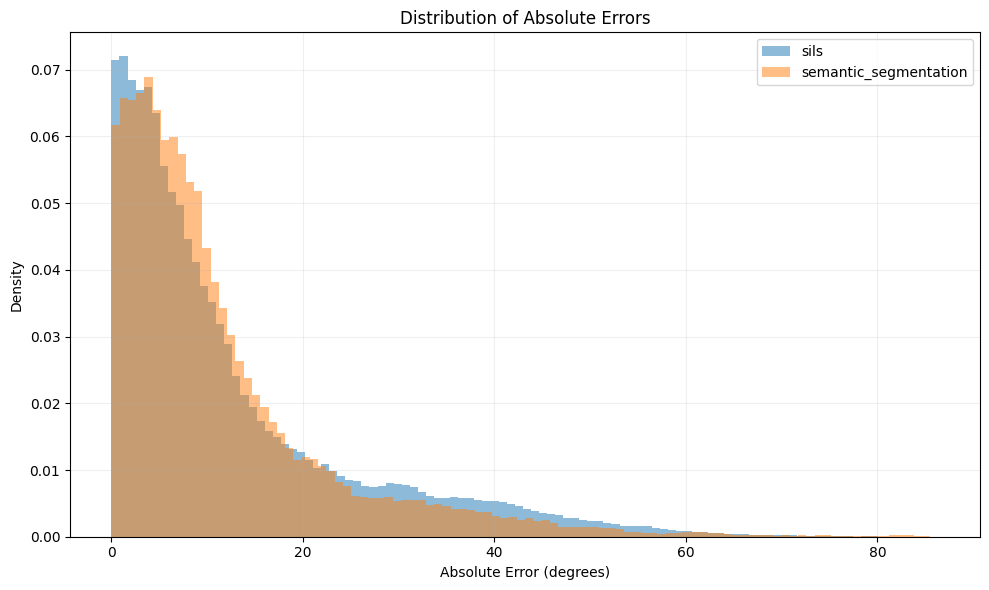

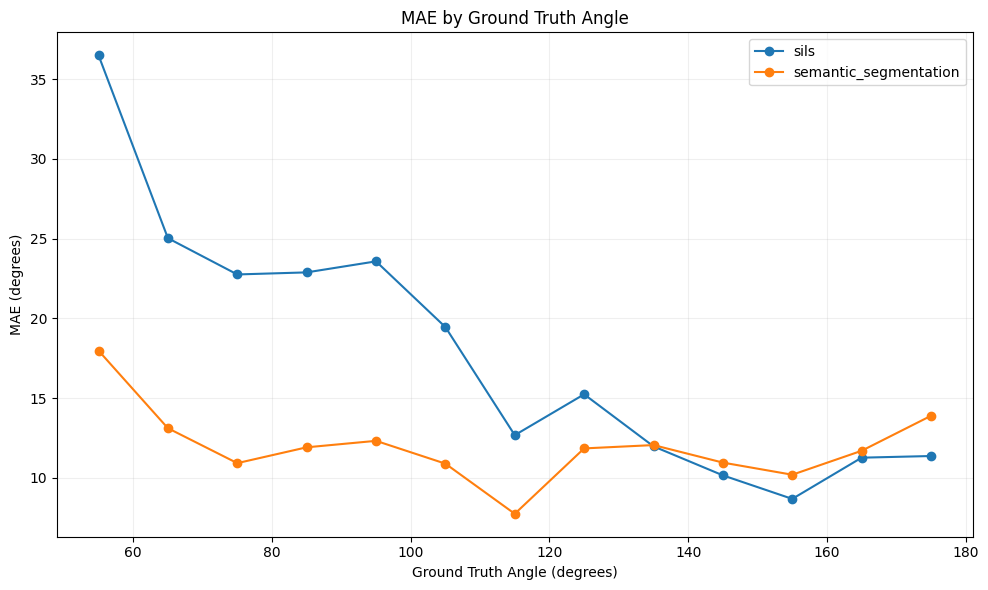

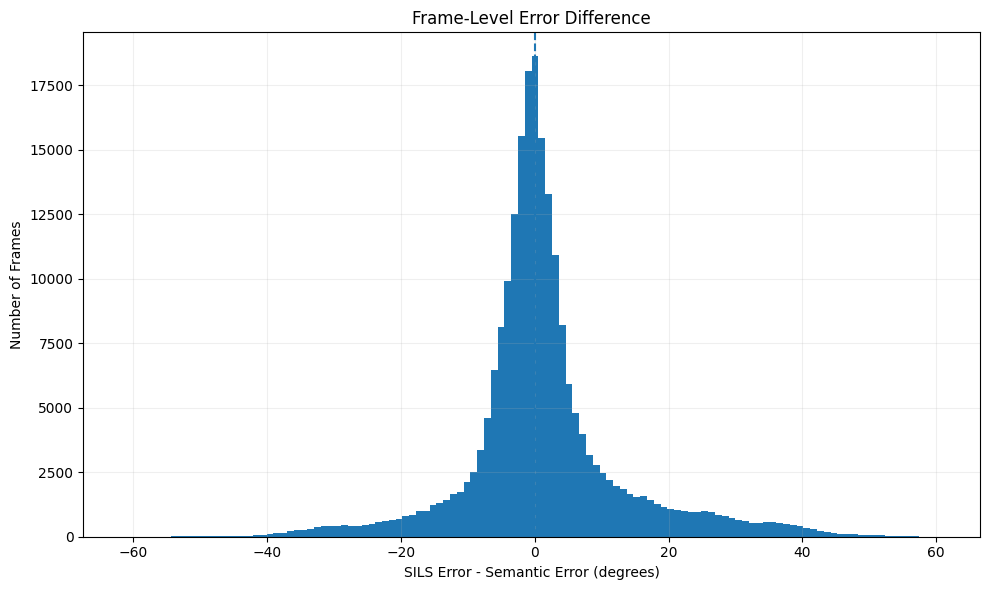

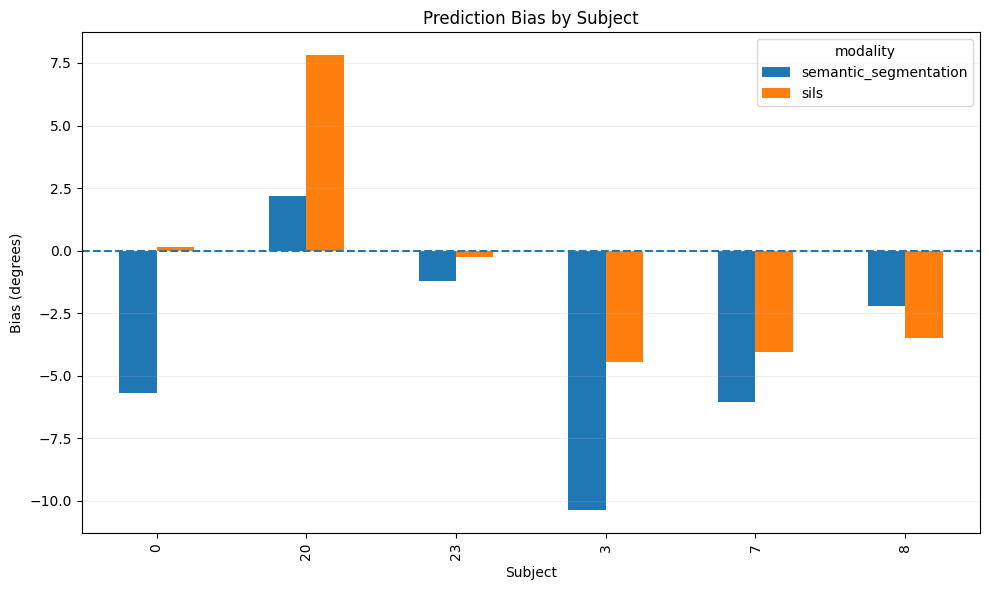

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plots_dir = results_root / "error_analysis_plots"
plots_dir.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(10, 6))

for modality, df in predictions.items():
    plt.hist(
        df["absolute_error"],
        bins=100,
        density=True,
        alpha=0.5,
        label=modality
    )

plt.xlabel("Absolute Error (degrees)")
plt.ylabel("Density")
plt.title("Distribution of Absolute Errors")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(plots_dir / "absolute_error_distribution.png", dpi=200)
plt.show()

plt.figure(figsize=(10, 6))

for modality, df in predictions.items():
    plot_df = df.copy()

    plot_df["angle_bin"] = pd.cut(
        plot_df["ground_truth_angle"],
        bins=np.arange(0, 191, 10)
    )

    grouped = plot_df.groupby(
        "angle_bin",
        observed=True
    )["absolute_error"].mean()

    centers = [
        interval.mid
        for interval in grouped.index
    ]

    plt.plot(
        centers,
        grouped.values,
        marker="o",
        label=modality
    )

plt.xlabel("Ground Truth Angle (degrees)")
plt.ylabel("MAE (degrees)")
plt.title("MAE by Ground Truth Angle")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(plots_dir / "mae_by_angle.png", dpi=200)
plt.show()


plt.figure(figsize=(10, 6))

plt.hist(
    frame_comparison["error_difference"],
    bins=120
)

plt.axvline(0, linestyle="--")

plt.xlabel("SILS Error - Semantic Error (degrees)")
plt.ylabel("Number of Frames")
plt.title("Frame-Level Error Difference")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(plots_dir / "frame_error_difference.png", dpi=200)
plt.show()


bias_data = []

for modality, df in predictions.items():
    temp = df.copy()

    temp["signed_error"] = (
        temp["predicted_angle"]
        - temp["ground_truth_angle"]
    )

    grouped = (
        temp.groupby("subject")["signed_error"]
        .mean()
        .reset_index()
    )

    grouped["modality"] = modality
    bias_data.append(grouped)

bias_df = pd.concat(bias_data)

bias_pivot = bias_df.pivot(
    index="subject",
    columns="modality",
    values="signed_error"
)

bias_pivot.plot(kind="bar", figsize=(10, 6))

plt.axhline(0, linestyle="--")
plt.ylabel("Bias (degrees)")
plt.xlabel("Subject")
plt.title("Prediction Bias by Subject")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.savefig(plots_dir / "bias_by_subject.png", dpi=200)
plt.show()

bias_df.to_csv(
    results_root / "bias_by_subject.csv",
    index=False
)

**Аналіз характеристик руху та повторень**

In [ ]:
!python -m src.analysis.compare_movement_descriptors

sils: subject=0, exercise=1, camera=cam0; MAE=4.22°, ROM error=1.07°, repetitions=2
sils: subject=0, exercise=1, camera=cam1; MAE=5.68°, ROM error=19.85°, repetitions=2
sils: subject=0, exercise=1, camera=cam2; MAE=6.06°, ROM error=13.30°, repetitions=2
sils: subject=0, exercise=1, camera=cam3; MAE=11.21°, ROM error=1.82°, repetitions=2
sils: subject=0, exercise=1, camera=cam4; MAE=13.31°, ROM error=21.11°, repetitions=2
sils: subject=0, exercise=2, camera=cam0; MAE=3.66°, ROM error=1.44°, repetitions=2
sils: subject=0, exercise=2, camera=cam1; MAE=8.18°, ROM error=15.23°, repetitions=2
sils: subject=0, exercise=2, camera=cam2; MAE=15.89°, ROM error=9.51°, repetitions=2
sils: subject=0, exercise=2, camera=cam3; MAE=9.37°, ROM error=0.68°, repetitions=2
sils: subject=0, exercise=2, camera=cam4; MAE=21.04°, ROM error=22.64°, repetitions=2
sils: subject=0, exercise=3, camera=cam0; MAE=7.56°, ROM error=9.12°, repetitions=0
sils: subject=0, exercise=3, camera=cam1; MAE=11.26°, ROM error=8.2

In [ ]:
from pathlib import Path
import pandas as pd

descriptor_dir = Path(
    "results/final_test/movement_descriptors"
)

files = [
    "movement_descriptors.csv",
    "repetition_descriptors.csv",
    "first_vs_last_repetition.csv",
]

for filename in files:
    df = pd.read_csv(descriptor_dir / filename)

    print(f"\n{filename}")
    print("Rows:", len(df))
    print("Missing values:", df.isna().sum().sum())

    display(df.groupby("modality").size().rename("rows"))

repetitions = pd.read_csv(
    descriptor_dir / "repetition_descriptors.csv"
)

repetition_summary = (
    repetitions.groupby("modality")
    .agg(
        repetitions=("repetition", "size"),
        mean_rom_error=("rom_absolute_error_deg", "mean"),
        median_rom_error=("rom_absolute_error_deg", "median")
    )
)

display(repetition_summary.round(3))

repetition_summary.to_csv(
    descriptor_dir / "repetition_summary.csv"
)


movement_descriptors.csv
Rows: 512
Missing values: 0


,rows
modality,
semantic_segmentation,256
sils,256



repetition_descriptors.csv
Rows: 748
Missing values: 0


,rows
modality,
semantic_segmentation,374
sils,374



first_vs_last_repetition.csv
Rows: 500
Missing values: 0


,rows
modality,
semantic_segmentation,250
sils,250


,repetitions,mean_rom_error,median_rom_error
modality,,,
semantic_segmentation,374,11.218,9.042
sils,374,15.686,11.968


In [ ]:
import numpy as np
import pandas as pd

descriptor_dir = Path(
    "results/final_test/movement_descriptors"
)

descriptors = pd.read_csv(
    descriptor_dir / "movement_descriptors.csv",
    dtype={"subject": str}
)

metrics = [
    "rom_deg",
    "mean_velocity_deg_s",
    "peak_velocity_deg_s",
    "smoothness_proxy"
]

for metric in metrics:
    descriptors[f"{metric}_absolute_error"] = (
        descriptors[f"gt_{metric}"]
        - descriptors[f"pred_{metric}"]
    ).abs()

summary = (
    descriptors.groupby("modality")[
        [f"{metric}_absolute_error" for metric in metrics]
    ]
    .agg(["mean", "median"])
)

display(summary.round(3))

descriptors.to_csv(
    descriptor_dir / "movement_descriptors_with_errors.csv",
    index=False
)

rom_deg_absolute_error         \
                                        mean median   
modality                                              
semantic_segmentation                  9.619  5.859   
sils                                  12.408  7.300   

                      mean_velocity_deg_s_absolute_error          \
                                                    mean  median   
modality                                                           
semantic_segmentation                             23.503  14.357   
sils                                              21.282  12.949   

                      peak_velocity_deg_s_absolute_error           \
                                                    mean   median   
modality                                                            
semantic_segmentation                            200.285  126.178   
sils                                             194.335  129.472   

                      smoothness_proxy_absolute_error           
                                                 mean   median  
modality                                                        
semantic_segmentation                        1285.318  901.420  
sils                                         1172.288  834.743

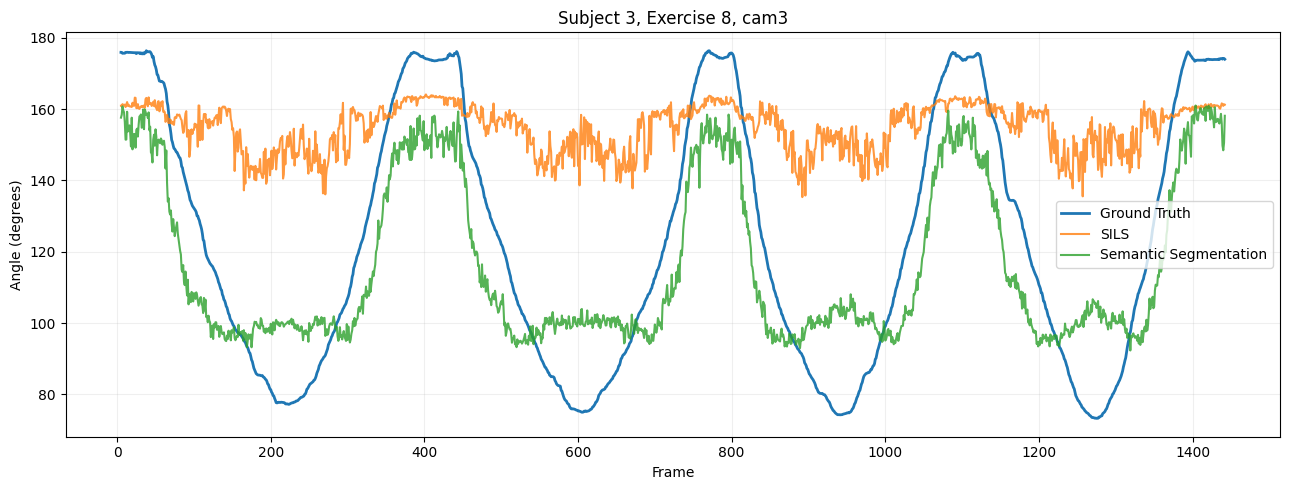

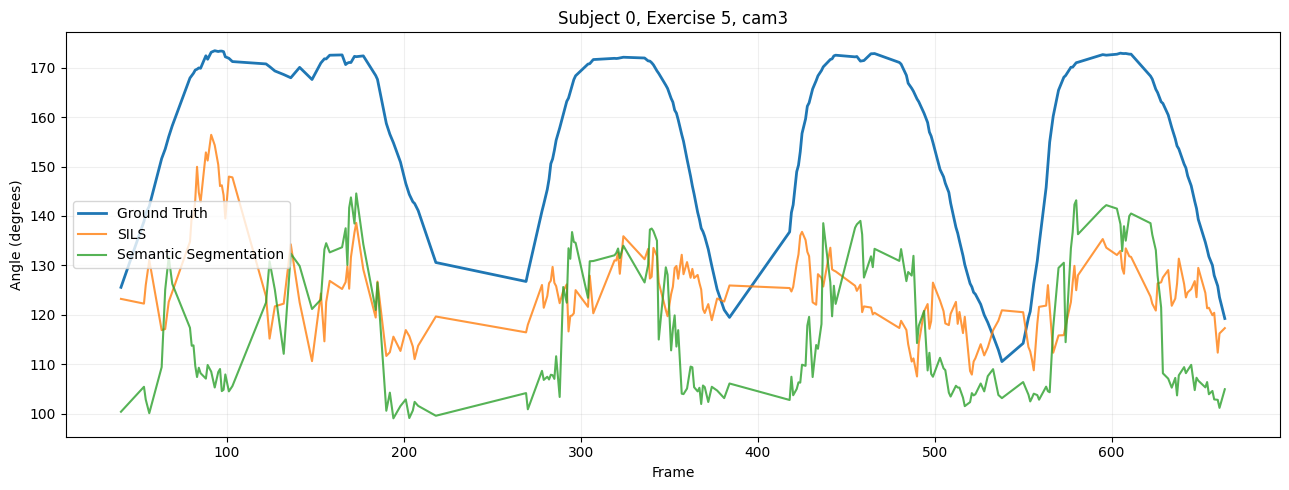

In [ ]:
import matplotlib.pyplot as plt

examples = [
    (3, 8, "cam3"),
    (0, 5, "cam3")
]

for subject, exercise, camera in examples:

    selected = merged[
        (merged["subject"].astype(str) == str(subject))
        & (merged["exercise"] == exercise)
        & (merged["camera"] == camera)
    ].sort_values("frame_id")

    plt.figure(figsize=(13, 5))

    plt.plot(
        selected["frame_id"],
        selected["ground_truth_angle_sils"],
        label="Ground Truth",
        linewidth=2
    )

    plt.plot(
        selected["frame_id"],
        selected["predicted_angle_sils"],
        label="SILS",
        alpha=0.8
    )

    plt.plot(
        selected["frame_id"],
        selected["predicted_angle_semantic"],
        label="Semantic Segmentation",
        alpha=0.8
    )

    plt.title(
        f"Subject {subject}, Exercise {exercise}, {camera}"
    )
    plt.xlabel("Frame")
    plt.ylabel("Angle (degrees)")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

In [ ]:
import numpy as np
import pandas as pd

from pathlib import Path
from scipy.signal import savgol_filter

output_dir = Path(
    "results/final_test/movement_descriptors"
)

output_dir.mkdir(parents=True, exist_ok=True)

FPS = 30
WINDOW = 11
POLYORDER = 3

records = []

for modality, data in predictions.items():

    for (subject, exercise, camera), group in data.groupby(
        ["subject", "exercise", "camera"]
    ):

        group = (
            group.sort_values("frame_id")
            .drop_duplicates("frame_id")
            .dropna(
                subset=[
                    "frame_id",
                    "ground_truth_angle",
                    "predicted_angle"
                ]
            )
        )

        frames = group["frame_id"].to_numpy(dtype=float)
        gt = group["ground_truth_angle"].to_numpy(dtype=float)
        pred = group["predicted_angle"].to_numpy(dtype=float)

        if len(frames) < WINDOW:
            continue

        if not (
            np.isfinite(frames).all()
            and np.isfinite(gt).all()
            and np.isfinite(pred).all()
        ):
            continue

        frame_deltas = np.diff(frames)

        if np.any(frame_deltas <= 0):
            continue


        if not np.all(frame_deltas == 1):
            continue

        gt_smooth = savgol_filter(
            gt,
            window_length=WINDOW,
            polyorder=POLYORDER
        )

        pred_smooth = savgol_filter(
            pred,
            window_length=WINDOW,
            polyorder=POLYORDER
        )

        for version, gt_angles, pred_angles in [
            ("raw", gt, pred),
            ("smoothed", gt_smooth, pred_smooth)
        ]:

            gt_velocity = np.diff(gt_angles) * FPS
            pred_velocity = np.diff(pred_angles) * FPS

            gt_acceleration = np.diff(gt_velocity) * FPS
            pred_acceleration = np.diff(pred_velocity) * FPS

            gt_mean_velocity = np.mean(np.abs(gt_velocity))
            pred_mean_velocity = np.mean(np.abs(pred_velocity))

            gt_peak_velocity = np.max(np.abs(gt_velocity))
            pred_peak_velocity = np.max(np.abs(pred_velocity))

            gt_smoothness = np.mean(np.abs(gt_acceleration))
            pred_smoothness = np.mean(np.abs(pred_acceleration))

            correlation = np.nan

            if np.std(gt_angles) > 0 and np.std(pred_angles) > 0:
                correlation = np.corrcoef(
                    gt_angles,
                    pred_angles
                )[0, 1]

            records.append({
                "modality": modality,
                "subject": subject,
                "exercise": exercise,
                "camera": camera,
                "version": version,
                "frames": len(frames),
                "angle_mae": np.mean(
                    np.abs(gt_angles - pred_angles)
                ),
                "rom_error": abs(
                    np.ptp(gt_angles) - np.ptp(pred_angles)
                ),
                "mean_velocity_error": abs(
                    gt_mean_velocity - pred_mean_velocity
                ),
                "peak_velocity_error": abs(
                    gt_peak_velocity - pred_peak_velocity
                ),
                "smoothness_error": abs(
                    gt_smoothness - pred_smoothness
                ),
                "correlation": correlation
            })

comparison_df = pd.DataFrame(records)

comparison_df.to_csv(
    output_dir / "raw_vs_smoothed_descriptors.csv",
    index=False
)

print("Rows:", len(comparison_df))
print("Sequences:", len(comparison_df) // 2)

Rows: 792
Sequences: 396


In [ ]:
metrics = [
    "angle_mae",
    "rom_error",
    "mean_velocity_error",
    "peak_velocity_error",
    "smoothness_error",
    "correlation"
]

summary = (
    comparison_df
    .groupby(["modality", "version"])[metrics]
    .agg(["mean", "median"])
)

display(summary.round(3))

summary.to_csv(
    output_dir / "raw_vs_smoothed_summary.csv"
)

angle_mae        rom_error         \
                                    mean median      mean median   
modality              version                                      
semantic_segmentation raw         10.927  8.517     9.497  5.771   
                      smoothed    10.899  8.516     9.404  6.061   
sils                  raw         13.261  8.734    12.457  6.664   
                      smoothed    13.233  8.734    12.287  6.710   

                               mean_velocity_error          \
                                              mean  median   
modality              version                                
semantic_segmentation raw                   24.188  14.696   
                      smoothed               6.059   2.594   
sils                  raw                   22.788  14.402   
                      smoothed               6.240   2.814   

                               peak_velocity_error          smoothness_error  \
                                              mean   median             mean   
modality              version                                                  
semantic_segmentation raw                  193.153  128.314         1320.397   
                      smoothed              46.220   25.530          186.251   
sils                  raw                  202.311  142.663         1255.181   
                      smoothed              48.063   25.149          184.065   

                                        correlation         
                                 median        mean median  
modality              version                               
semantic_segmentation raw       929.886       0.471  0.613  
                      smoothed  122.954       0.478  0.647  
sils                  raw       888.512       0.416  0.589  
                      smoothed  132.202       0.420  0.615

In [ ]:
correlation_comparison = (
    comparison_df[
        comparison_df["version"] == "raw"
    ]
    .pivot_table(
        index=["subject", "exercise", "camera"],
        columns="modality",
        values="correlation"
    )
    .dropna()
)

correlation_comparison["semantic_advantage"] = (
    correlation_comparison["semantic_segmentation"]
    - correlation_comparison["sils"]
)

display(
    correlation_comparison
    .sort_values("semantic_advantage", ascending=False)
    .head(10)
)

print(
    "Semantic better correlation:",
    (correlation_comparison["semantic_advantage"] > 0).sum()
)

print(
    "SILS better correlation:",
    (correlation_comparison["semantic_advantage"] < 0).sum()
)

print(
    "Mean correlation advantage:",
    correlation_comparison["semantic_advantage"].mean()
)

modality                 semantic_segmentation      sils  semantic_advantage
subject exercise camera                                                     
20      9        cam2                 0.800379 -0.843943            1.644322
        13       cam2                 0.831176 -0.582243            1.413420
3       9        cam4                 0.393706 -0.771821            1.165527
        13       cam2                 0.766696 -0.328140            1.094837
20      13       cam3                 0.207137 -0.841332            1.048469
        15       cam2                 0.669955 -0.347198            1.017153
0       14       cam2                 0.537857 -0.452763            0.990620
3       9        cam2                 0.654003 -0.296542            0.950545
20      9        cam1                 0.624029 -0.193252            0.817281
0       13       cam2                 0.314363 -0.498309            0.812672

Semantic better correlation: 121
SILS better correlation: 77
Mean correlation advantage: 0.05453186048834943


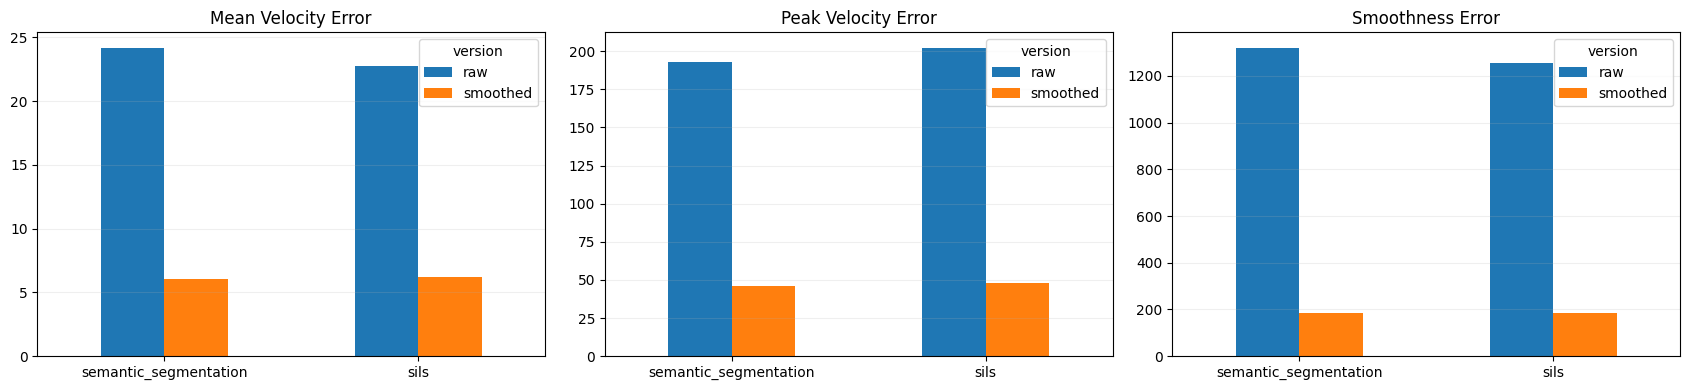

In [ ]:
import matplotlib.pyplot as plt

plot_metrics = [
    "mean_velocity_error",
    "peak_velocity_error",
    "smoothness_error"
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 4)
)

for ax, metric in zip(axes, plot_metrics):

    plot_data = (
        comparison_df
        .groupby(["modality", "version"])[metric]
        .mean()
        .unstack("version")
    )

    plot_data.plot(
        kind="bar",
        ax=ax,
        rot=0
    )

    ax.set_title(metric.replace("_", " ").title())
    ax.set_xlabel("")
    ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

plt.savefig(
    output_dir / "smoothing_impact.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import pandas as pd
import numpy as np

descriptor_dir = Path(
    "results/final_test/movement_descriptors"
)

reps = pd.read_csv(
    descriptor_dir / "first_vs_last_repetition.csv",
    dtype={"subject": str}
)

keys = ["modality", "subject", "exercise", "camera"]

first = (
    reps.sort_values("repetition")
    .groupby(keys)
    .first()
    .reset_index()
)

last = (
    reps.sort_values("repetition")
    .groupby(keys)
    .last()
    .reset_index()
)

comparison = first.merge(
    last,
    on=keys,
    suffixes=("_first", "_last")
)

comparison = comparison[
    comparison["repetition_first"]
    < comparison["repetition_last"]
].copy()

comparison["gt_rom_change"] = (
    comparison["gt_rom_deg_last"]
    - comparison["gt_rom_deg_first"]
)

comparison["pred_rom_change"] = (
    comparison["pred_rom_deg_last"]
    - comparison["pred_rom_deg_first"]
)

comparison["rom_change_error"] = (
    comparison["gt_rom_change"]
    - comparison["pred_rom_change"]
).abs()

comparison["gt_velocity_change"] = (
    comparison["gt_peak_velocity_deg_s_last"]
    - comparison["gt_peak_velocity_deg_s_first"]
)

comparison["pred_velocity_change"] = (
    comparison["pred_peak_velocity_deg_s_last"]
    - comparison["pred_peak_velocity_deg_s_first"]
)

comparison["velocity_change_error"] = (
    comparison["gt_velocity_change"]
    - comparison["pred_velocity_change"]
).abs()

comparison.to_csv(
    descriptor_dir / "first_last_change_comparison.csv",
    index=False
)

summary = (
    comparison.groupby("modality")
    .agg(
        sequences=("rom_change_error", "size"),
        mean_rom_change_error=("rom_change_error", "mean"),
        median_rom_change_error=("rom_change_error", "median"),
        mean_velocity_change_error=("velocity_change_error", "mean"),
        median_velocity_change_error=("velocity_change_error", "median")
    )
)

display(summary.round(3))

summary.to_csv(
    descriptor_dir / "first_last_change_summary.csv"
)

,sequences,mean_rom_change_error,median_rom_change_error,mean_velocity_change_error,median_velocity_change_error
modality,,,,,
semantic_segmentation,125,3.378,2.062,65.307,35.759
sils,125,3.342,2.152,68.293,40.481
